Fit a unimodal model to time series data using PCA to reduce dimension in the time series.

In-sample prediction is good as expected. Out of sample prediction shows varying degrees of bias, and increased variance as expected

In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math
from typing import Optional
import itertools
import random

import seaborn as sns
import pandas as pd

import torch
import pyro
from pyro.infer import Predictive

from mmbo.mode.timeseries import TSPCA
from mmbo.mode.vae import VAE
from mmbo.examples.testfunc import timeseries_stat, timeseries_full
from mmbo.nn import RegBNN, RegBNNGuide

In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            print("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
            #logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return losses

## Generate train and test data

Test data will be both in-sample and out-of-sample to varying degrees

In [4]:
X_vals = [-1.5, -1.0, -0.5, 0.5, 1.0, 1.5]
amp_log = math.log(0.25)
n_train = len(X_vals) ** 3
X_train = torch.zeros((n_train, 4))
noise = 0.05
res = 200

for i, xi in enumerate(itertools.product(X_vals, X_vals, X_vals)):
    X_train[i,0] = xi[0]
    X_train[i,1] = xi[1]
    X_train[i,2] = amp_log
    X_train[i,3] = xi[2]

Y_train = timeseries_full(X_train, noise = noise, res = res).unsqueeze(-2)

In [5]:
Y_pca = TSPCA(Y_train, n_components = 0.95)
Y_train_pca = Y_pca.encode(Y_train)

In [6]:
X_vals_test = [-2.0, -1.0, 0.0, 1.0, 2.0]
n_test = len(X_vals_test) ** 3
X_test = torch.zeros((n_test, 4))
noise_test = 0.05
test_type = [None] * n_test

for i, xi in enumerate(itertools.product(X_vals_test, X_vals_test, X_vals_test)):
    X_test[i,0] = xi[0]
    X_test[i,1] = xi[1]
    X_test[i,2] = amp_log
    X_test[i,3] = xi[2]
    if (xi[0] in [-1.0, 1.0]) and (xi[1] in [-1.0, 1.0]) and (xi[2] in [-1.0, 1.0]):
        test_type[i] = "in_sample"
    elif (X_test[i].abs() == 2.0).any():
        test_type[i] = "out_hull"
    else:
        test_type[i] = "in_hull"

Y_test = timeseries_full(X_test, noise = noise, res = res).unsqueeze(-2)

Y_test_pca = Y_pca.encode(Y_test)

In [7]:
in_sample = [i for i in range(n_test) if test_type[i] == "in_sample"]
in_hull = [i for i in range(n_test) if test_type[i] == "in_hull"]
out_hull = [i for i in range(n_test) if test_type[i] == "out_hull"]


## Visualize train data

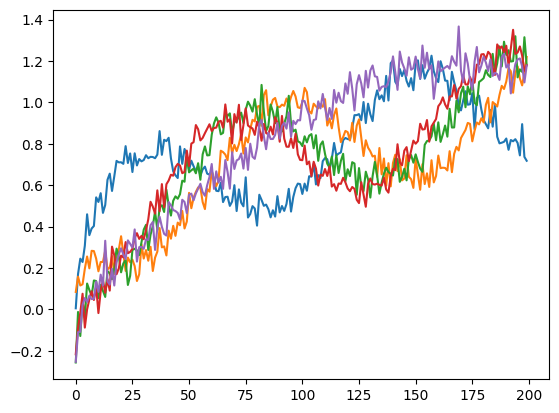

In [8]:
plt.plot(Y_train.squeeze(-2)[50:55].mT)

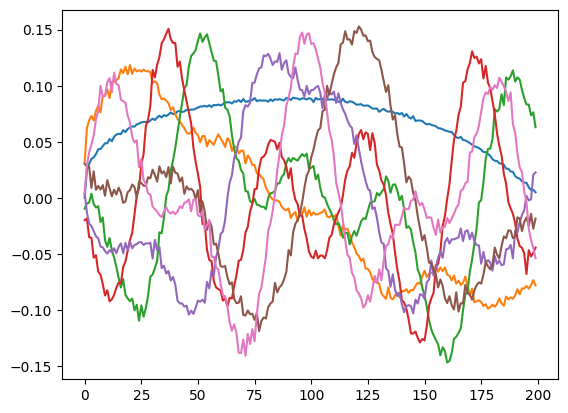

In [9]:
Y_train_pca.shape
Y_pca._pca.components_
plt.plot(Y_pca._pca.components_.mT)

## Visualize test data

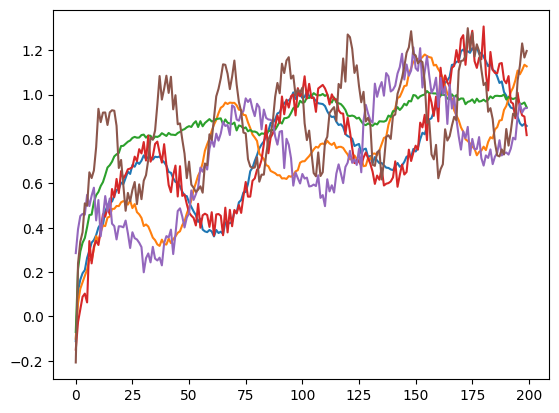

In [10]:
testidx = [in_sample[0], in_hull[0], out_hull[0]]

Y_test_decoded = Y_pca.decode(Y_test_pca)
plt.plot(Y_test_decoded[testidx].squeeze(-2).mT)
plt.plot(Y_test[testidx].squeeze(-2).mT)

In [11]:
# Variance explained in test data
1.0 - (Y_test - Y_test_decoded).var() / Y_test.var()

tensor(0.9240)

## Build and train unimodal model

In [12]:
method = "svi"
#method = "mcmc"

In [13]:
model = RegBNN.from_data(X_train, Y_train_pca, hidden_widths = [256, 256])
guide = RegBNNGuide(model)

In [14]:
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model, guide, adam, elbo)
hmc = pyro.infer.NUTS(model.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 50151.1 +/- 29460.5 (slope = -50553.659 +/- 426.958 loss/k-iter, p-value = 0.000) 
Step 2000, Elbo loss: 18478.0 +/- 10101.9 (slope = -17317.570 +/- 154.340 loss/k-iter, p-value = 0.000) 
Step 3000, Elbo loss: 7434.0 +/- 3706.8 (slope = -6359.839 +/- 54.170 loss/k-iter, p-value = 0.000) 
Step 4000, Elbo loss: 3271.3 +/- 1434.6 (slope = -2450.449 +/- 25.581 loss/k-iter, p-value = 0.000) 
Step 5000, Elbo loss: 1649.8 +/- 578.3 (slope = -971.084 +/- 15.408 loss/k-iter, p-value = 0.000) 
Step 6000, Elbo loss: 1002.2 +/- 263.2 (slope = -399.330 +/- 13.889 loss/k-iter, p-value = 0.000) 
Step 7000, Elbo loss: 716.4 +/- 162.9 (slope = -194.506 +/- 12.924 loss/k-iter, p-value = 0.000) 
Step 8000, Elbo loss: 574.1 +/- 127.8 (slope = -99.609 +/- 12.512 loss/k-iter, p-value = 0.000) 
Step 9000, Elbo loss: 493.9 +/- 121.9 (slope = -72.752 +/- 12.538 loss/k-iter, p-value = 0.000) 
Step 10000, Elbo loss: 443.5 +/- 115.5 (slope = -45.202 +/- 12.336 loss/k-iter, p-value = 0.000) 


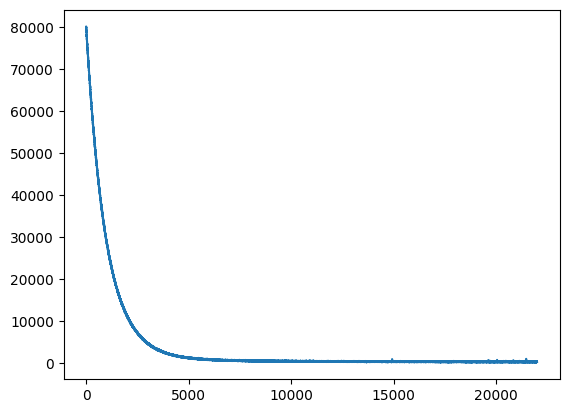

In [15]:
if method == "mcmc":
    mcmc = pyro.infer.MCMC(hmc, num_samples = 100, warmup_steps = 100)
    mcmc.run(X_pred = X_test)
    pred = Predictive(model, mcmc.get_samples())
    Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    with param_store.scope() as params:
        losses = do_svi(svi)
        plt.plot(losses)
        guide.eval()
        pred = Predictive(model, guide = guide, num_samples = 100)
        Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
Y_pred = Y_pca.decode(Y_pred_pca)

In [16]:
def plot_predictions(Y_test, Y_pred, series_idx):
    Y_true = Y_test[series_idx].squeeze()
    Y_pred = Y_pred[:,series_idx].squeeze(-2).mT
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    ylims = [1.5*Y_pred.min().detach() - 0.5*Y_pred.max().detach(), 1.5*Y_pred.max().detach() - 0.5*Y_pred.min().detach()]
    plt.ylim(ylims)
    # Plot true function
    ax.plot(Y_true, 'k-', linewidth=3, label="true function", zorder = 20)
    # Plot data points
    ax.plot(Y_pred, 'b-', linewidth=1, alpha=0.5, label="estimates", zorder = 15)

def plot_predictions_pca(Y_test_pca, Y_pred_pca, series_idx):
    Y_true_pca = Y_test_pca[series_idx]
    Y_pred_pca = Y_pred_pca[:,series_idx]
    colnames = [f"PC{n}" for n in range(Y_pred_pca.shape[-1])]
    data = pd.DataFrame(Y_pred_pca, columns=colnames)
    data["Type"] = "Pred"
    data_true = pd.DataFrame(Y_true_pca.unsqueeze(0), columns=colnames)
    data_true["Type"] = "True"
    g = sns.pairplot(pd.concat([data, data_true]), hue="Type", height = 1.5, diag_kind="hist")

In [17]:
random.shuffle(in_sample)
random.shuffle(in_hull)
random.shuffle(out_hull)

idx = 0

### In-sample

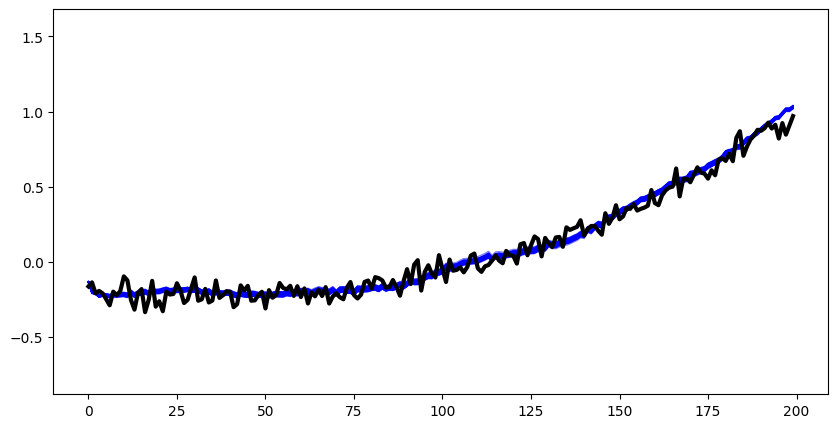

In [18]:
plot_predictions(Y_test, Y_pred, in_sample[idx])

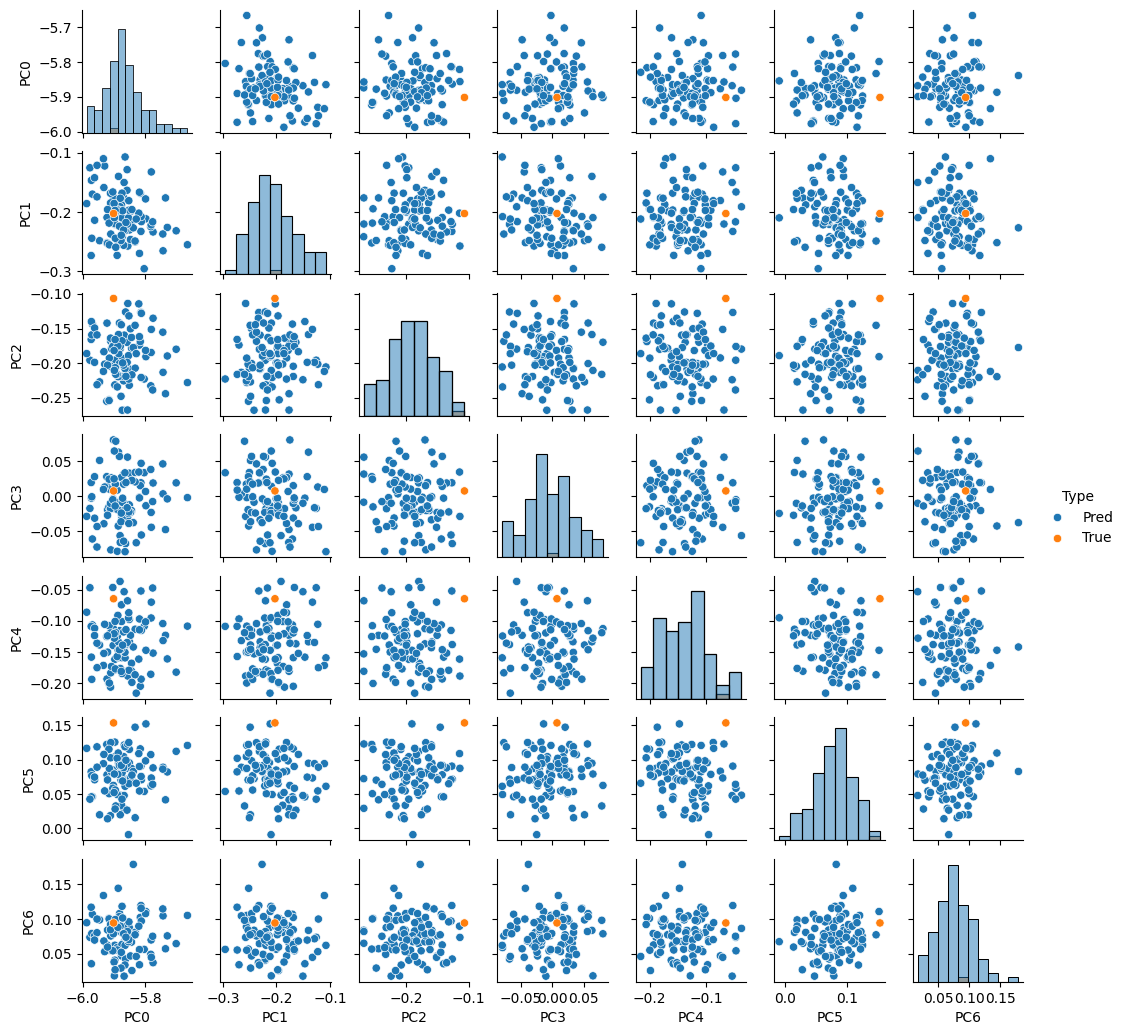

In [19]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, in_sample[idx])

### Out of sample but within the convex hull

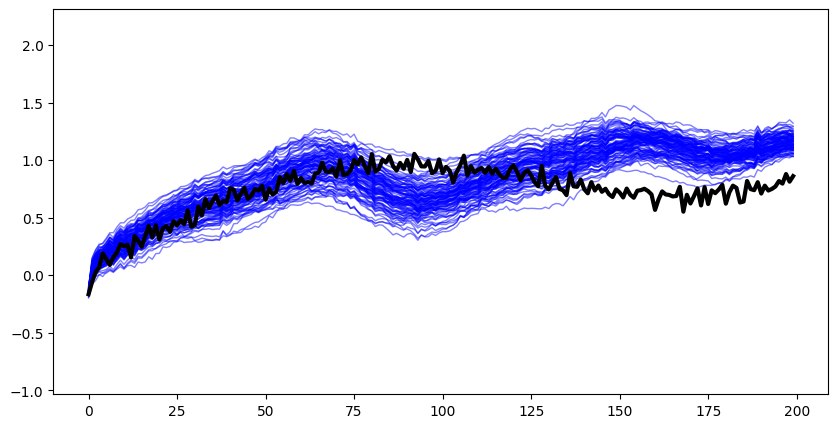

In [20]:
plot_predictions(Y_test, Y_pred, in_hull[idx])

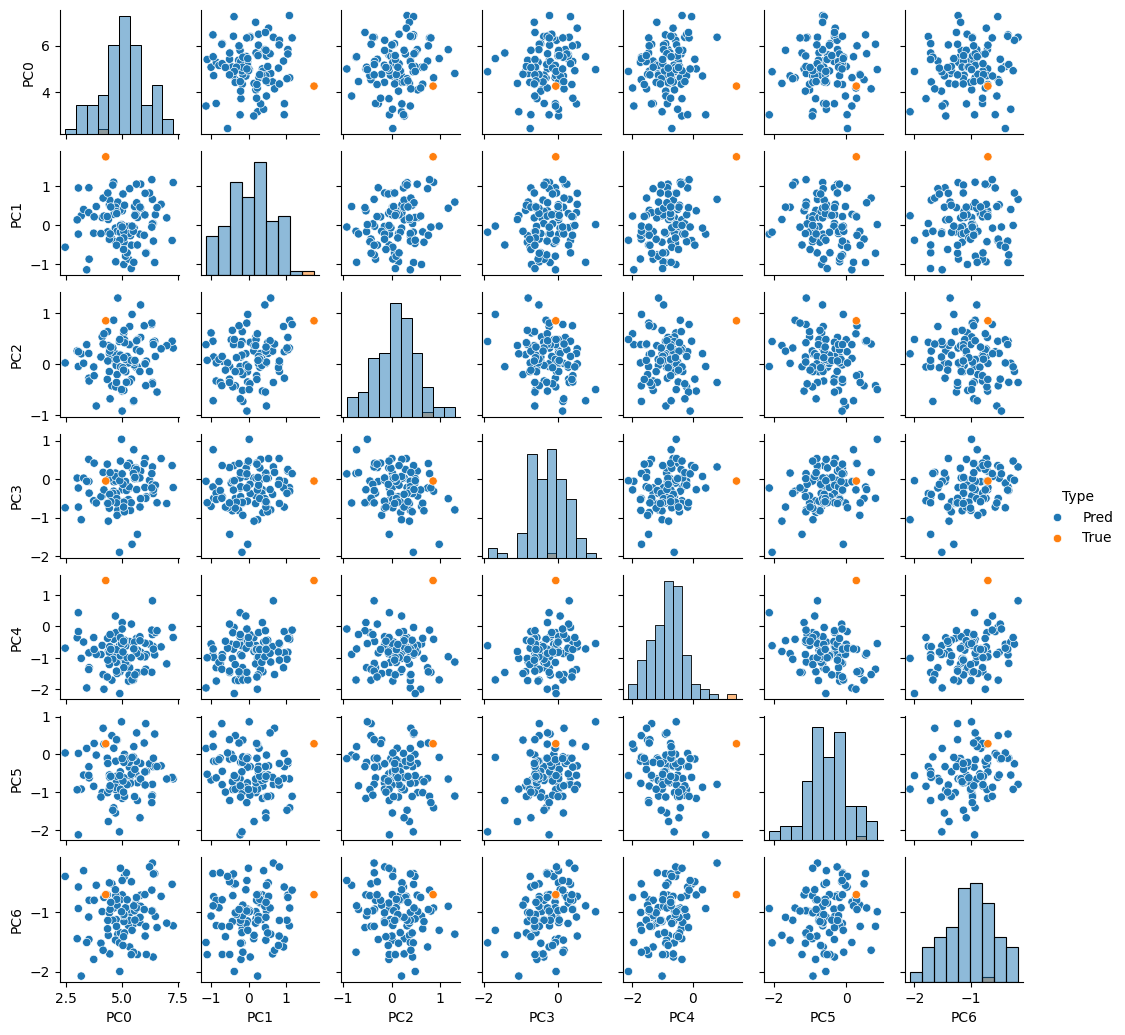

In [21]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, in_hull[idx])

### Out of the convex hull

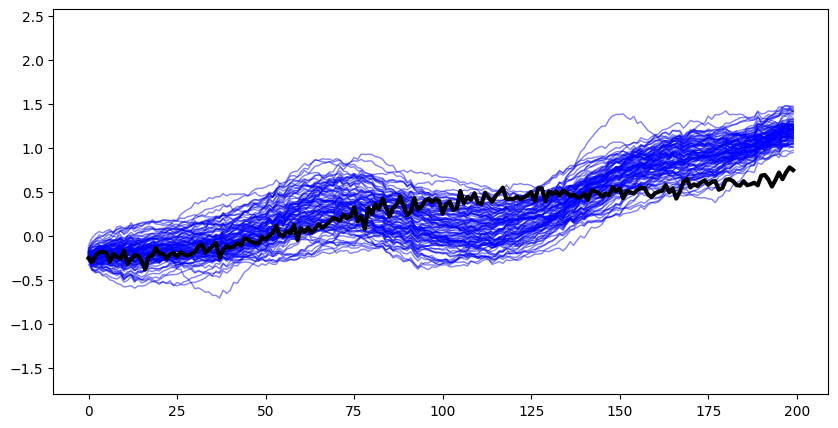

In [22]:
plot_predictions(Y_test, Y_pred, out_hull[idx])

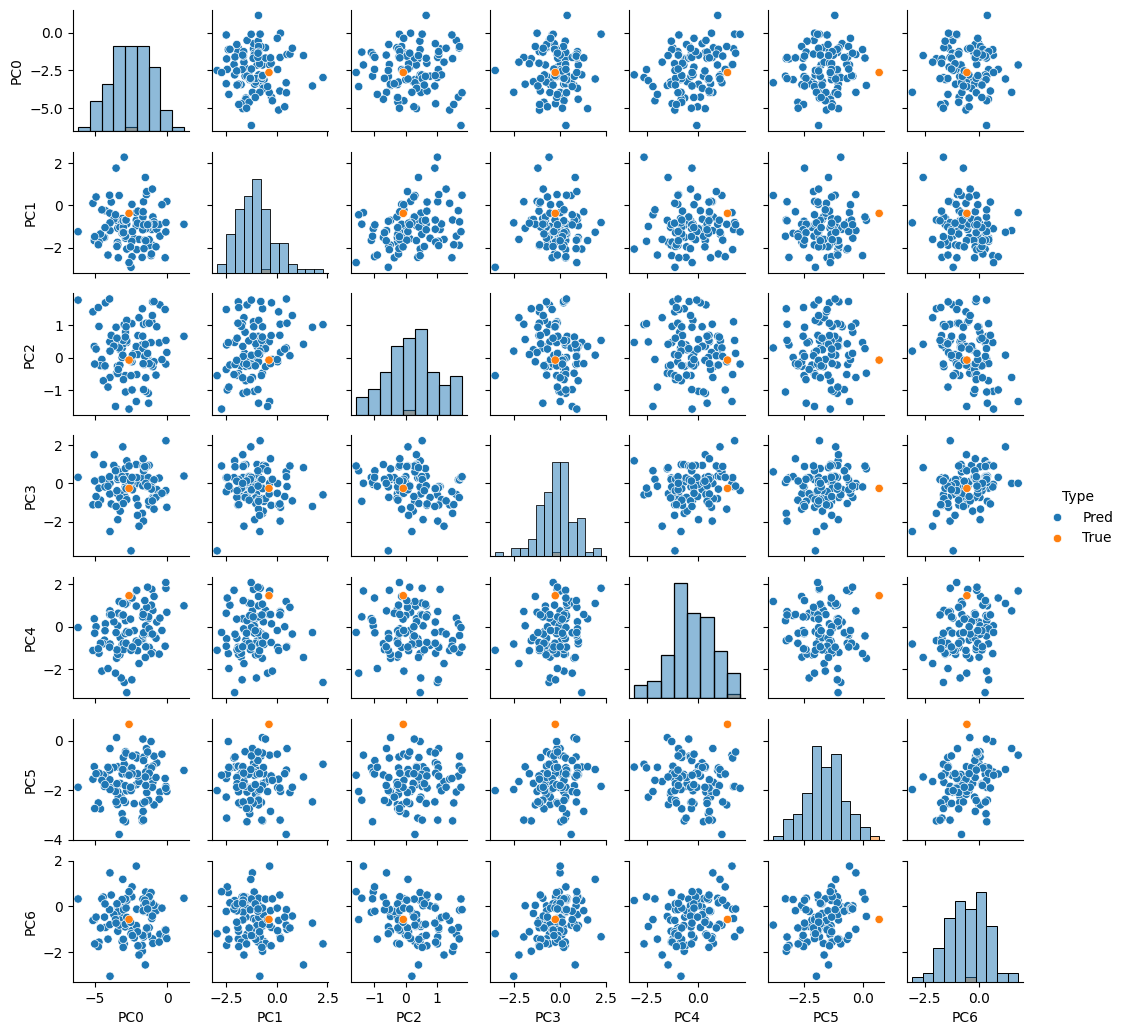

In [23]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, out_hull[idx])

## Repeat with an "oracle" PCA

Capture the variation of unseen observations in the PCA (but still train the surrogate only on the training data.)

In [24]:
Y_pca2 = TSPCA(torch.cat([Y_train, Y_test], dim=0))
Y_train_pca2 = Y_pca2.encode(Y_train)
Y_test_pca2 = Y_pca2.encode(Y_test)

In [25]:
model2 = RegBNN.from_data(X_train, Y_train_pca2, hidden_widths = [256, 256])
guide2 = RegBNNGuide(model2)

In [26]:
svi2 = pyro.infer.SVI(model2, guide2, adam, elbo)
hmc2 = pyro.infer.NUTS(model2.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 49891.6 +/- 29351.3 (slope = -50353.920 +/- 431.205 loss/k-iter, p-value = 0.000) 
Step 2000, Elbo loss: 18398.1 +/- 10047.7 (slope = -17234.176 +/- 149.139 loss/k-iter, p-value = 0.000) 
Step 3000, Elbo loss: 7376.2 +/- 3701.5 (slope = -6345.638 +/- 56.433 loss/k-iter, p-value = 0.000) 
Step 4000, Elbo loss: 3252.9 +/- 1413.6 (slope = -2416.782 +/- 24.332 loss/k-iter, p-value = 0.000) 
Step 5000, Elbo loss: 1664.0 +/- 561.4 (slope = -941.211 +/- 15.322 loss/k-iter, p-value = 0.000) 
Step 6000, Elbo loss: 1037.3 +/- 255.4 (slope = -391.199 +/- 13.044 loss/k-iter, p-value = 0.000) 
Step 7000, Elbo loss: 766.1 +/- 152.9 (slope = -180.749 +/- 12.243 loss/k-iter, p-value = 0.000) 
Step 8000, Elbo loss: 632.3 +/- 119.8 (slope = -103.074 +/- 11.398 loss/k-iter, p-value = 0.000) 
Step 9000, Elbo loss: 553.8 +/- 107.5 (slope = -69.256 +/- 10.931 loss/k-iter, p-value = 0.000) 
Step 10000, Elbo loss: 512.8 +/- 103.8 (slope = -35.709 +/- 11.148 loss/k-iter, p-value = 0.000) 

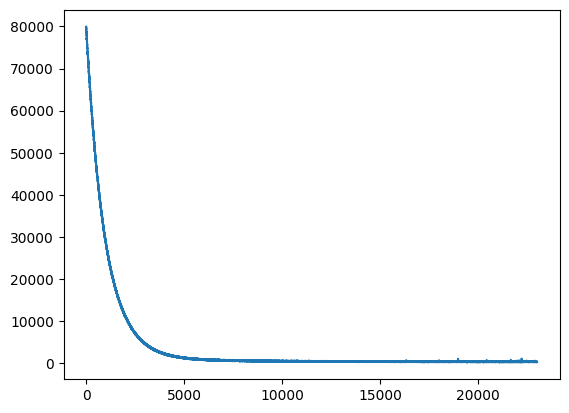

In [27]:
if method == "mcmc":
    mcmc2 = pyro.infer.MCMC(hmc2, num_samples = 100, warmup_steps = 100)
    mcmc2.run(X_pred = X_test)
    pred2 = Predictive(model2, mcmc2.get_samples())
    Y_pred_pca2 = pred2.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    with param_store.scope() as params2:
        losses2 = do_svi(svi2)
        plt.plot(losses2)
        guide2.eval()
        pred2 = Predictive(model2, guide = guide2, num_samples = 100)
        Y_pred_pca2 = pred2.get_samples(X_pred = X_test)['mu_pred']
Y_pred2 = Y_pca2.decode(Y_pred_pca2)

### In-sample

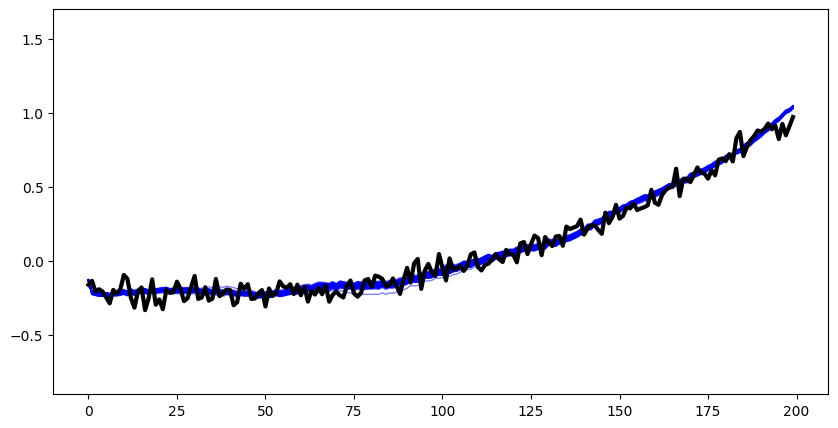

In [28]:
plot_predictions(Y_test, Y_pred2, in_sample[idx])

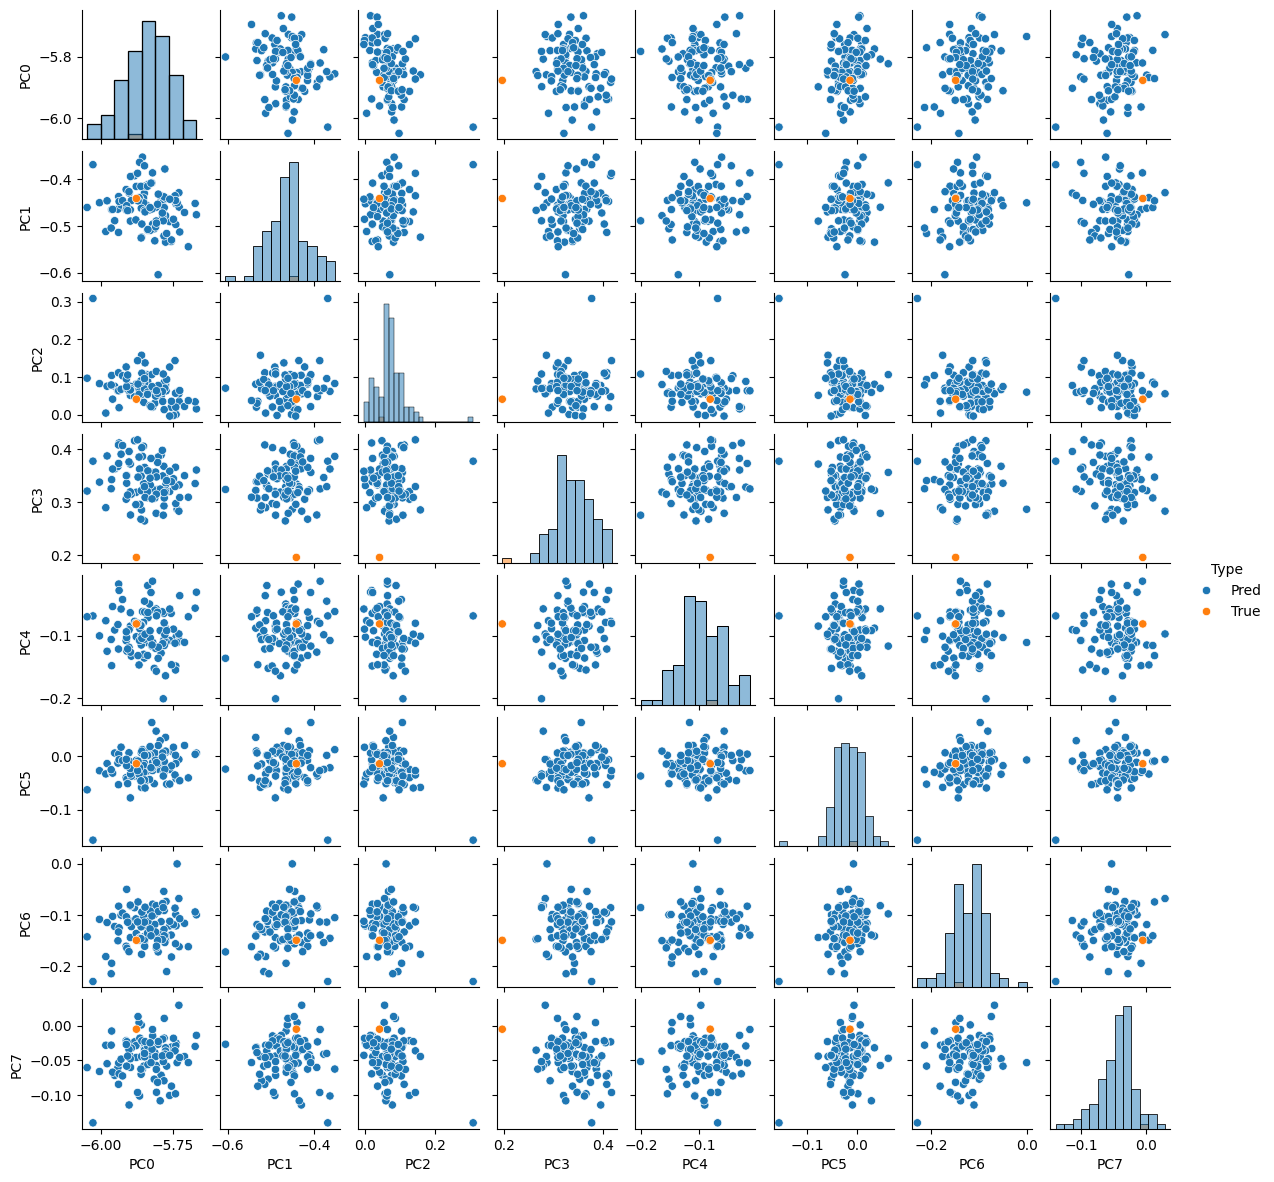

In [29]:
plot_predictions_pca(Y_test_pca2, Y_pred_pca2, in_sample[idx])

### Out of sample but within convex hull

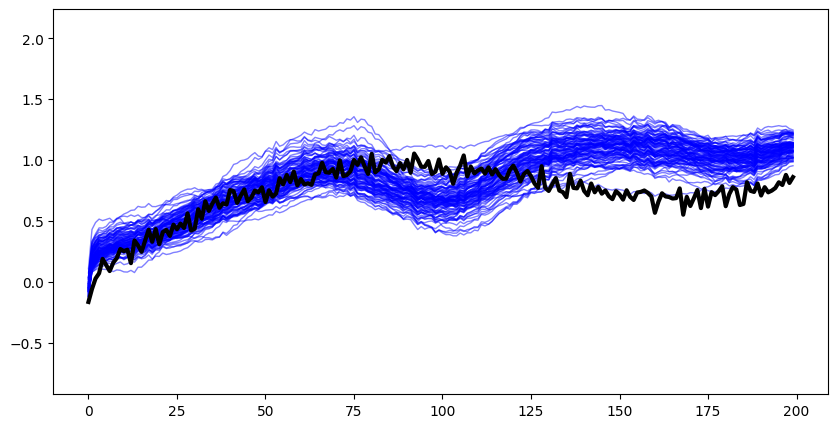

In [30]:
plot_predictions(Y_test, Y_pred2, in_hull[idx])

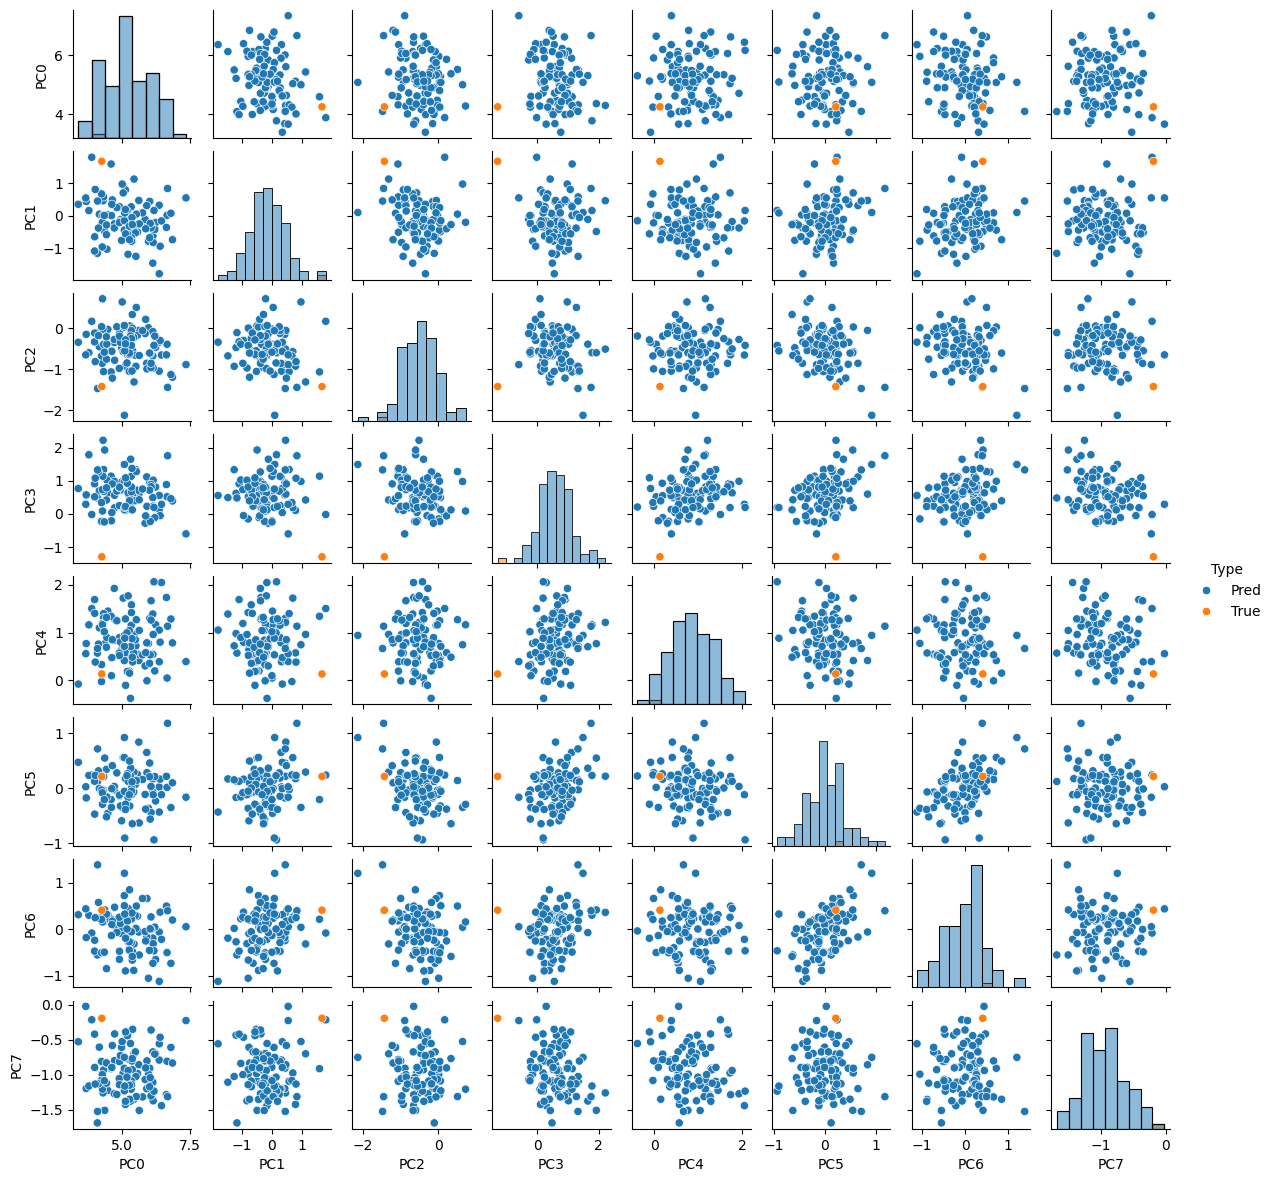

In [31]:
plot_predictions_pca(Y_test_pca2, Y_pred_pca2, in_hull[idx])

### Out of convex hull

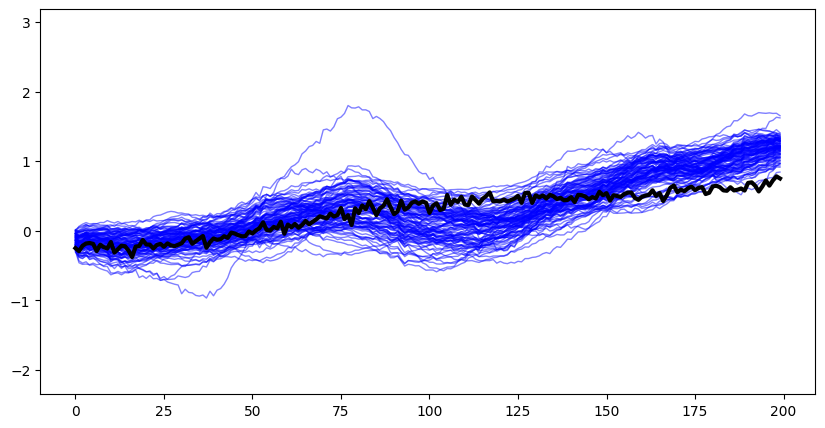

In [32]:
plot_predictions(Y_test, Y_pred2, out_hull[idx])

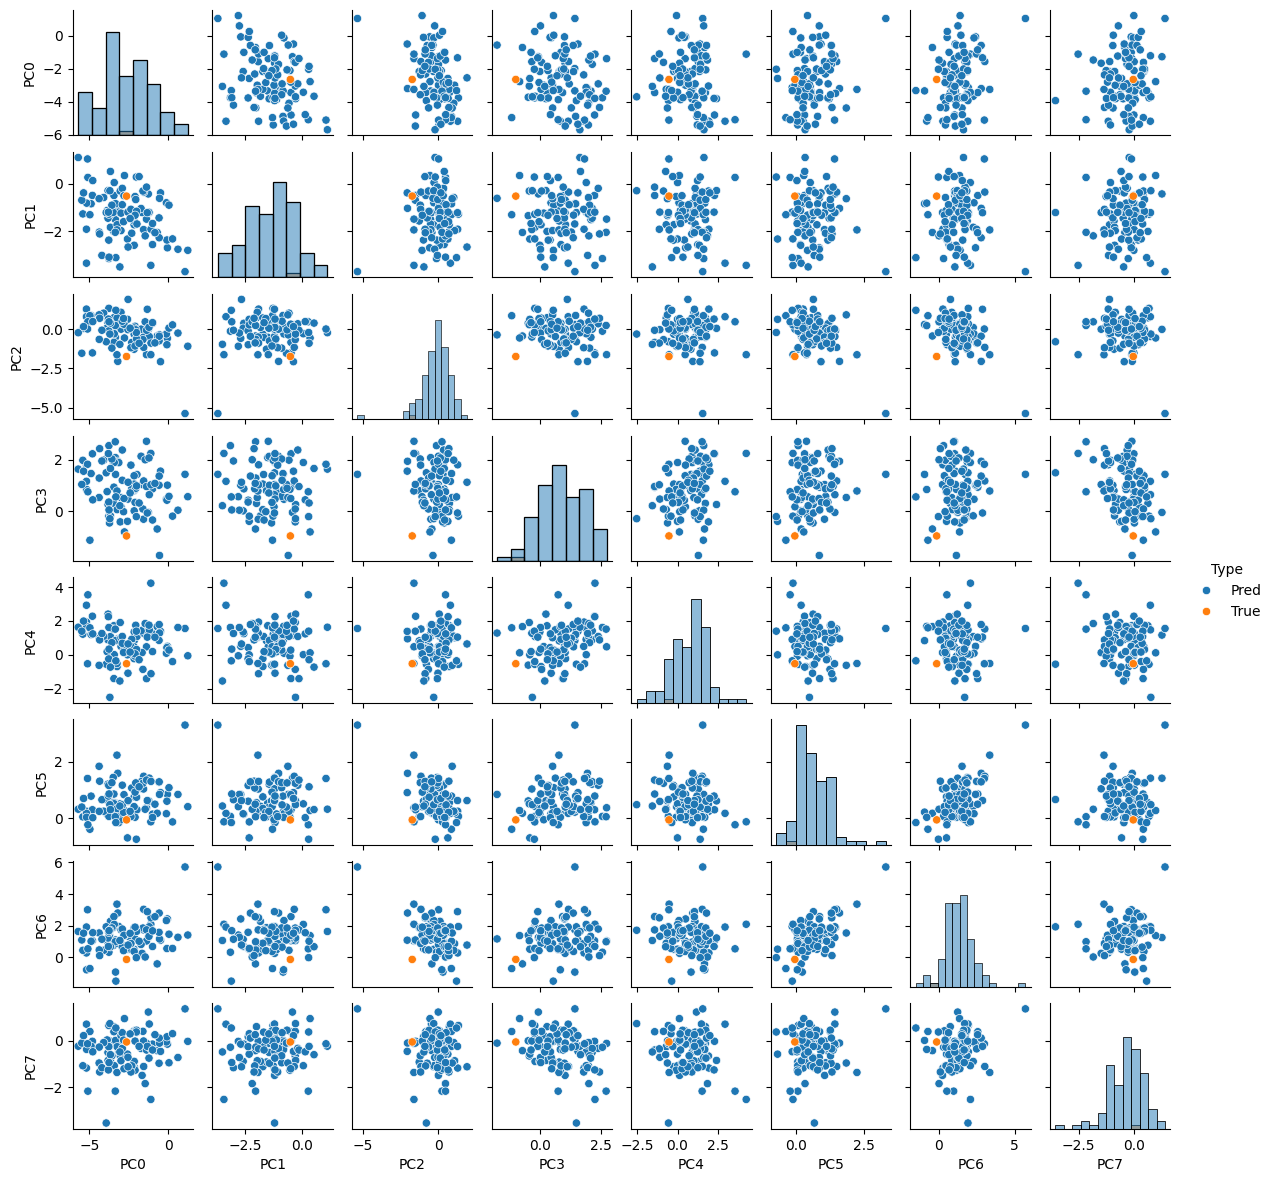

In [33]:
plot_predictions_pca(Y_test_pca2, Y_pred_pca2, out_hull[idx])

## Testing and Misc Junk

In [34]:
params['params']['layers.0.0.loc'][0:20]

tensor([[-2.7775e-01,  8.0669e-04,  3.3979e-01,  2.9583e-02, -1.0401e-01],
        [ 4.9353e-01, -2.3618e-04,  7.0558e-01,  2.2684e-01, -2.2206e-01],
        [-5.6429e-02,  7.0817e-03,  6.6189e-02,  6.4747e-02, -2.9229e-01],
        [ 1.2425e+00, -8.9735e-03,  1.4114e+00,  6.5609e-01,  3.0164e-01],
        [ 2.2479e-01, -8.9133e-01, -1.4070e-02, -2.4084e-01, -7.0503e-03],
        [-1.6654e-01, -1.2499e-02,  1.6389e-01, -4.1898e-02, -1.2534e-01],
        [ 2.2792e-03,  9.8436e-01, -2.7824e-03, -8.8491e-01, -4.8819e-04],
        [ 8.2361e-01,  2.6049e-02, -2.6445e-01,  8.4633e-02,  9.2405e-01],
        [-4.0414e-01, -6.9236e-03, -7.2475e-02, -1.5157e-01, -1.2318e-01],
        [-1.7593e-01, -1.2585e-03,  2.0437e-01, -7.5548e-02,  7.2104e-03],
        [ 7.9969e-02,  2.0427e-02,  1.4090e-01,  4.0982e-02, -4.3802e-01],
        [ 2.4393e-01,  9.5794e-04, -7.2920e-01, -1.3442e-01,  7.4455e-01],
        [ 1.1178e+00,  2.3320e-03,  1.1827e+00,  1.2924e-01,  2.0134e-01],
        [ 7.9673e-01, -1.